# P1 baseline — EMA 12/26 cross signals, 2026 Q1–Q3

Daily candles with EMA 12 (orange) and EMA 26 (purple). **Buy** ▲ when EMA 12 crosses above EMA 26; **sell** ▼ when it crosses below.
Markers sit on the signal bar, which is a completed candle; the earliest fill is the next bar's open (listed in the table).

- EMAs warm up from 2025 Q4 so both lines are valid on the first bar of 2026.
- Signals only: no MACD filter, positions or P&L yet.

In [1]:
from helpers.replayer_bars import DATA_SYMBOL
from helpers.ema_signals import ema_cross, plot_ema_signals, signal_table

SYMBOLS = ["BTC", "ETH", "XAUT", "QQQ"]
START, END, WARMUP = "2026Q1", "2026Q3", "2025Q4"
LABEL = "2026 Q1–Q3"

bars = {symbol: ema_cross(symbol, START, END, WARMUP) for symbol in SYMBOLS}
for symbol, price in bars.items():
    s = price["signal"]
    print(f"{symbol:<5} ({DATA_SYMBOL[symbol]}): {len(price)} bars, {(s > 0).sum()} buy / {(s < 0).sum()} sell signals, "
          f"EMA 12 {'above' if price['ema_fast'].iloc[0] > price['ema_slow'].iloc[0] else 'below'} EMA 26 on {price.index[0]:%Y-%m-%d}")

BTC   (BTC): 273 bars, 7 buy / 6 sell signals, EMA 12 below EMA 26 on 2026-01-01
ETH   (ETH): 273 bars, 4 buy / 3 sell signals, EMA 12 below EMA 26 on 2026-01-01
XAUT  (XAUUSD): 193 bars, 1 buy / 2 sell signals, EMA 12 above EMA 26 on 2026-01-02
QQQ   (QQQ): 187 bars, 3 buy / 3 sell signals, EMA 12 above EMA 26 on 2026-01-02


In [2]:
for symbol, price in bars.items():
    print(f"\n{symbol}")
    print(signal_table(price).to_string(float_format="{:,.2f}".format))


BTC
               side  signal_close    fill_bar  fill_open
bar_open_time                                           
2026-01-05      buy     93,862.90  2026-01-06  93,862.90
2026-01-24     sell     89,227.70  2026-01-25  89,227.70
2026-03-15      buy     72,812.40  2026-03-16  72,812.40
2026-03-22     sell     67,862.00  2026-03-23  67,862.00
2026-03-23      buy     70,898.70  2026-03-24  70,898.70
2026-03-26     sell     68,820.10  2026-03-27  68,820.10
2026-04-09      buy     71,788.90  2026-04-10  71,788.90
2026-05-22     sell     75,540.30  2026-05-23  75,540.30
2026-07-15      buy     64,756.40  2026-07-16  64,756.40
2026-08-01     sell     62,823.30  2026-08-02  62,823.30
2026-08-06      buy     64,320.40  2026-08-07  64,320.40
2026-08-12     sell     63,482.90  2026-08-13  63,482.90
2026-08-19      buy     69,338.40  2026-08-20  69,338.40

ETH
               side  signal_close    fill_bar  fill_open
bar_open_time                                           
2026-01-04      buy  

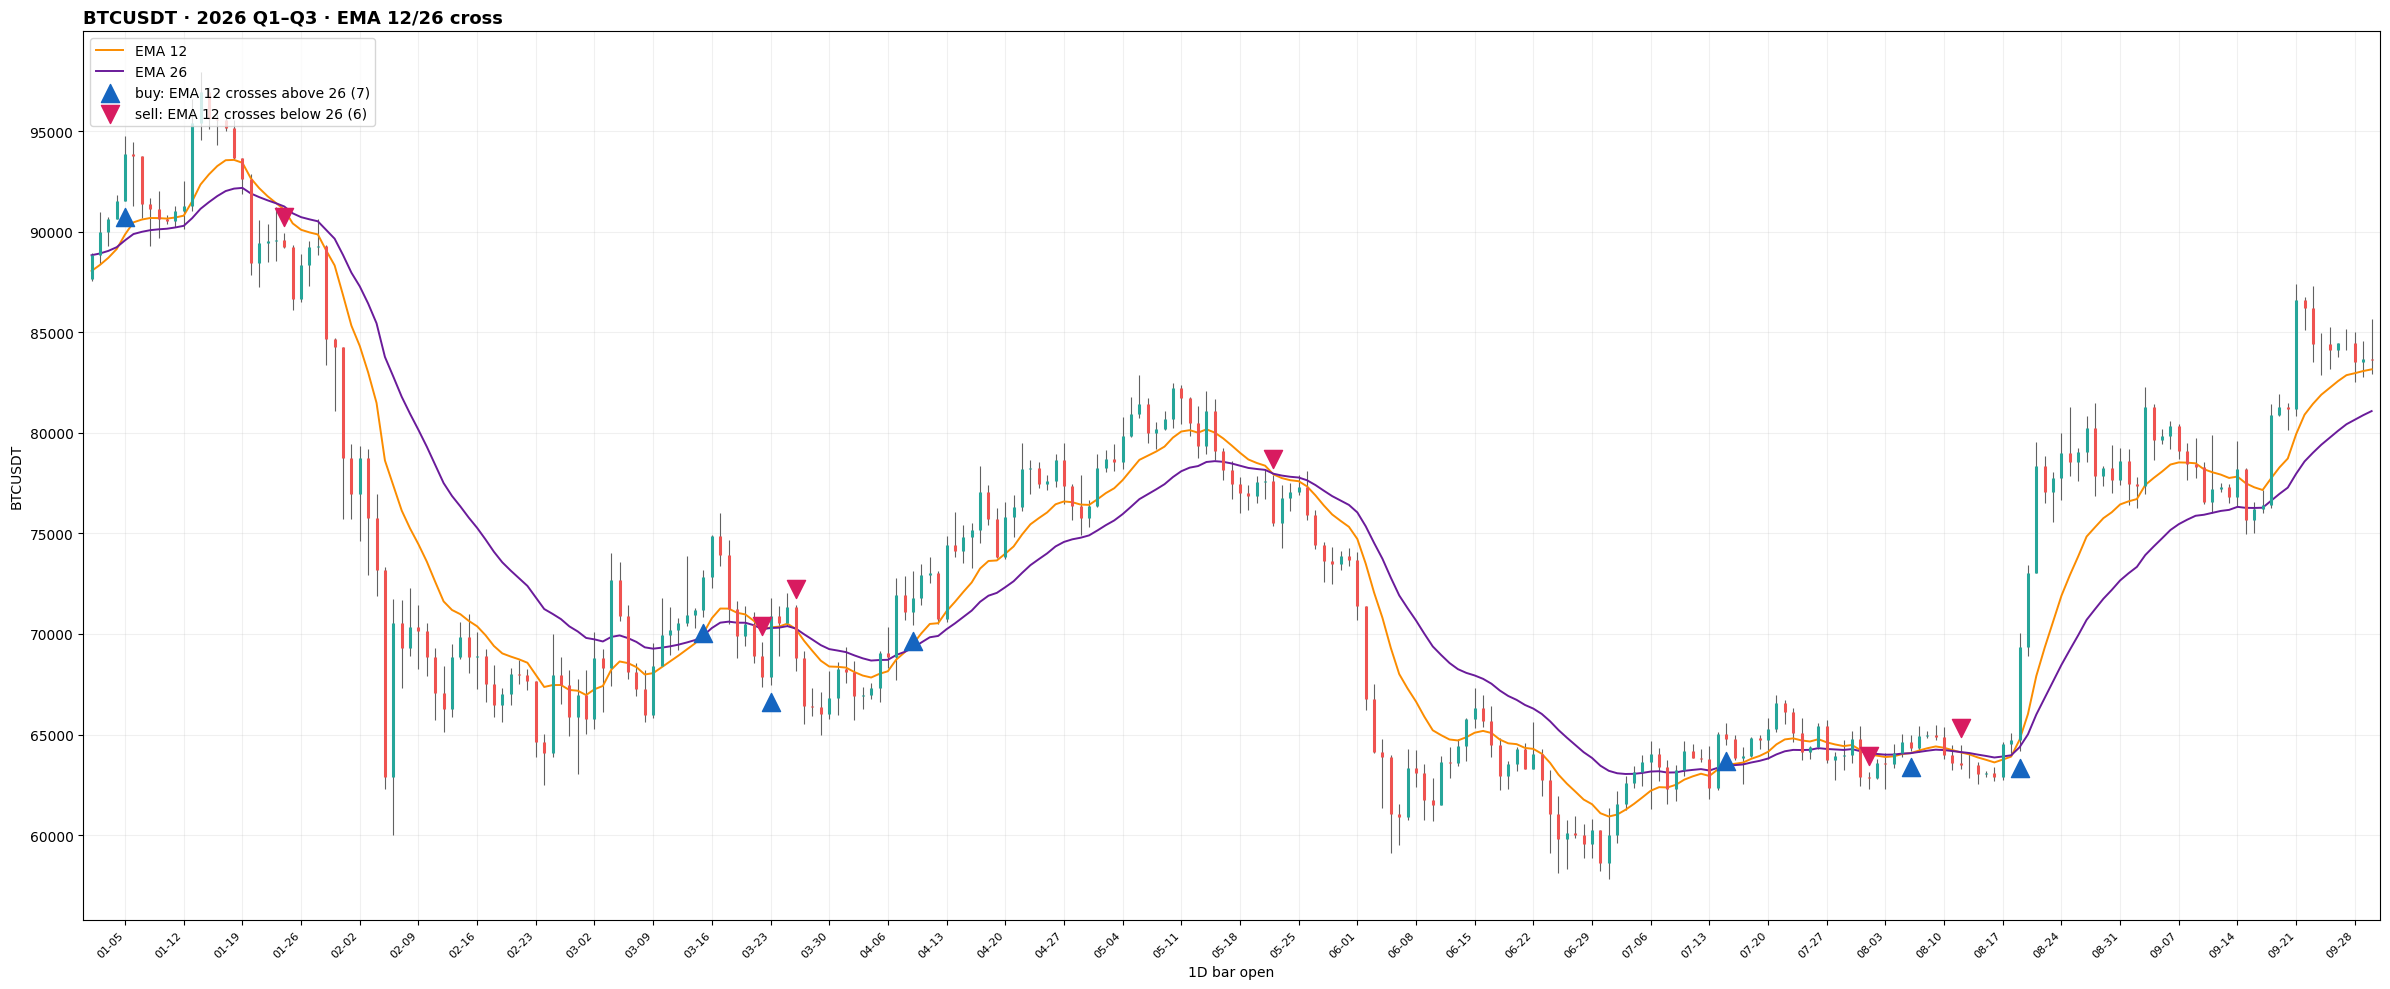

In [3]:
plot_ema_signals(bars["BTC"], f"BTCUSDT · {LABEL} · EMA 12/26 cross", "BTCUSDT")

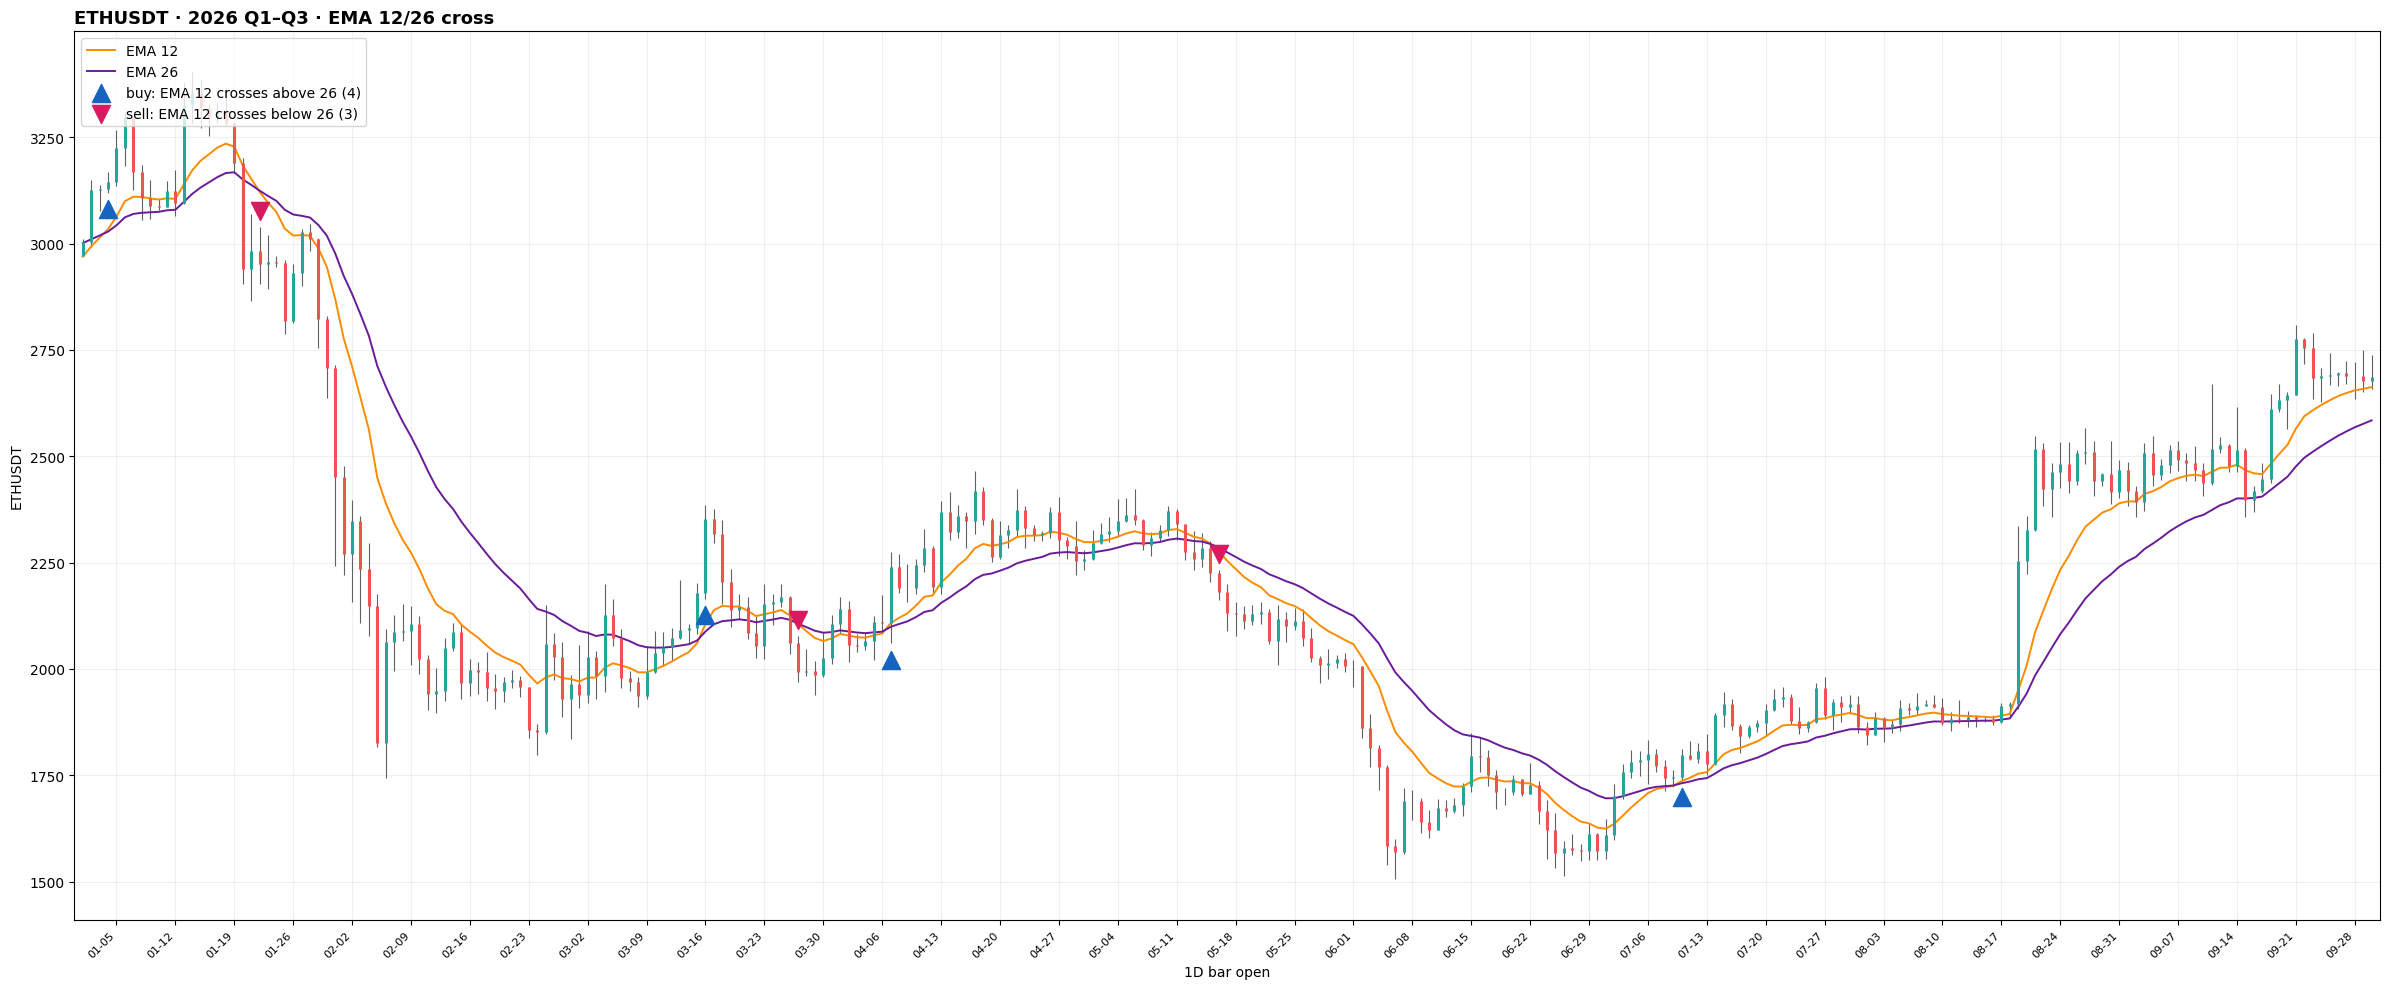

In [4]:
plot_ema_signals(bars["ETH"], f"ETHUSDT · {LABEL} · EMA 12/26 cross", "ETHUSDT")

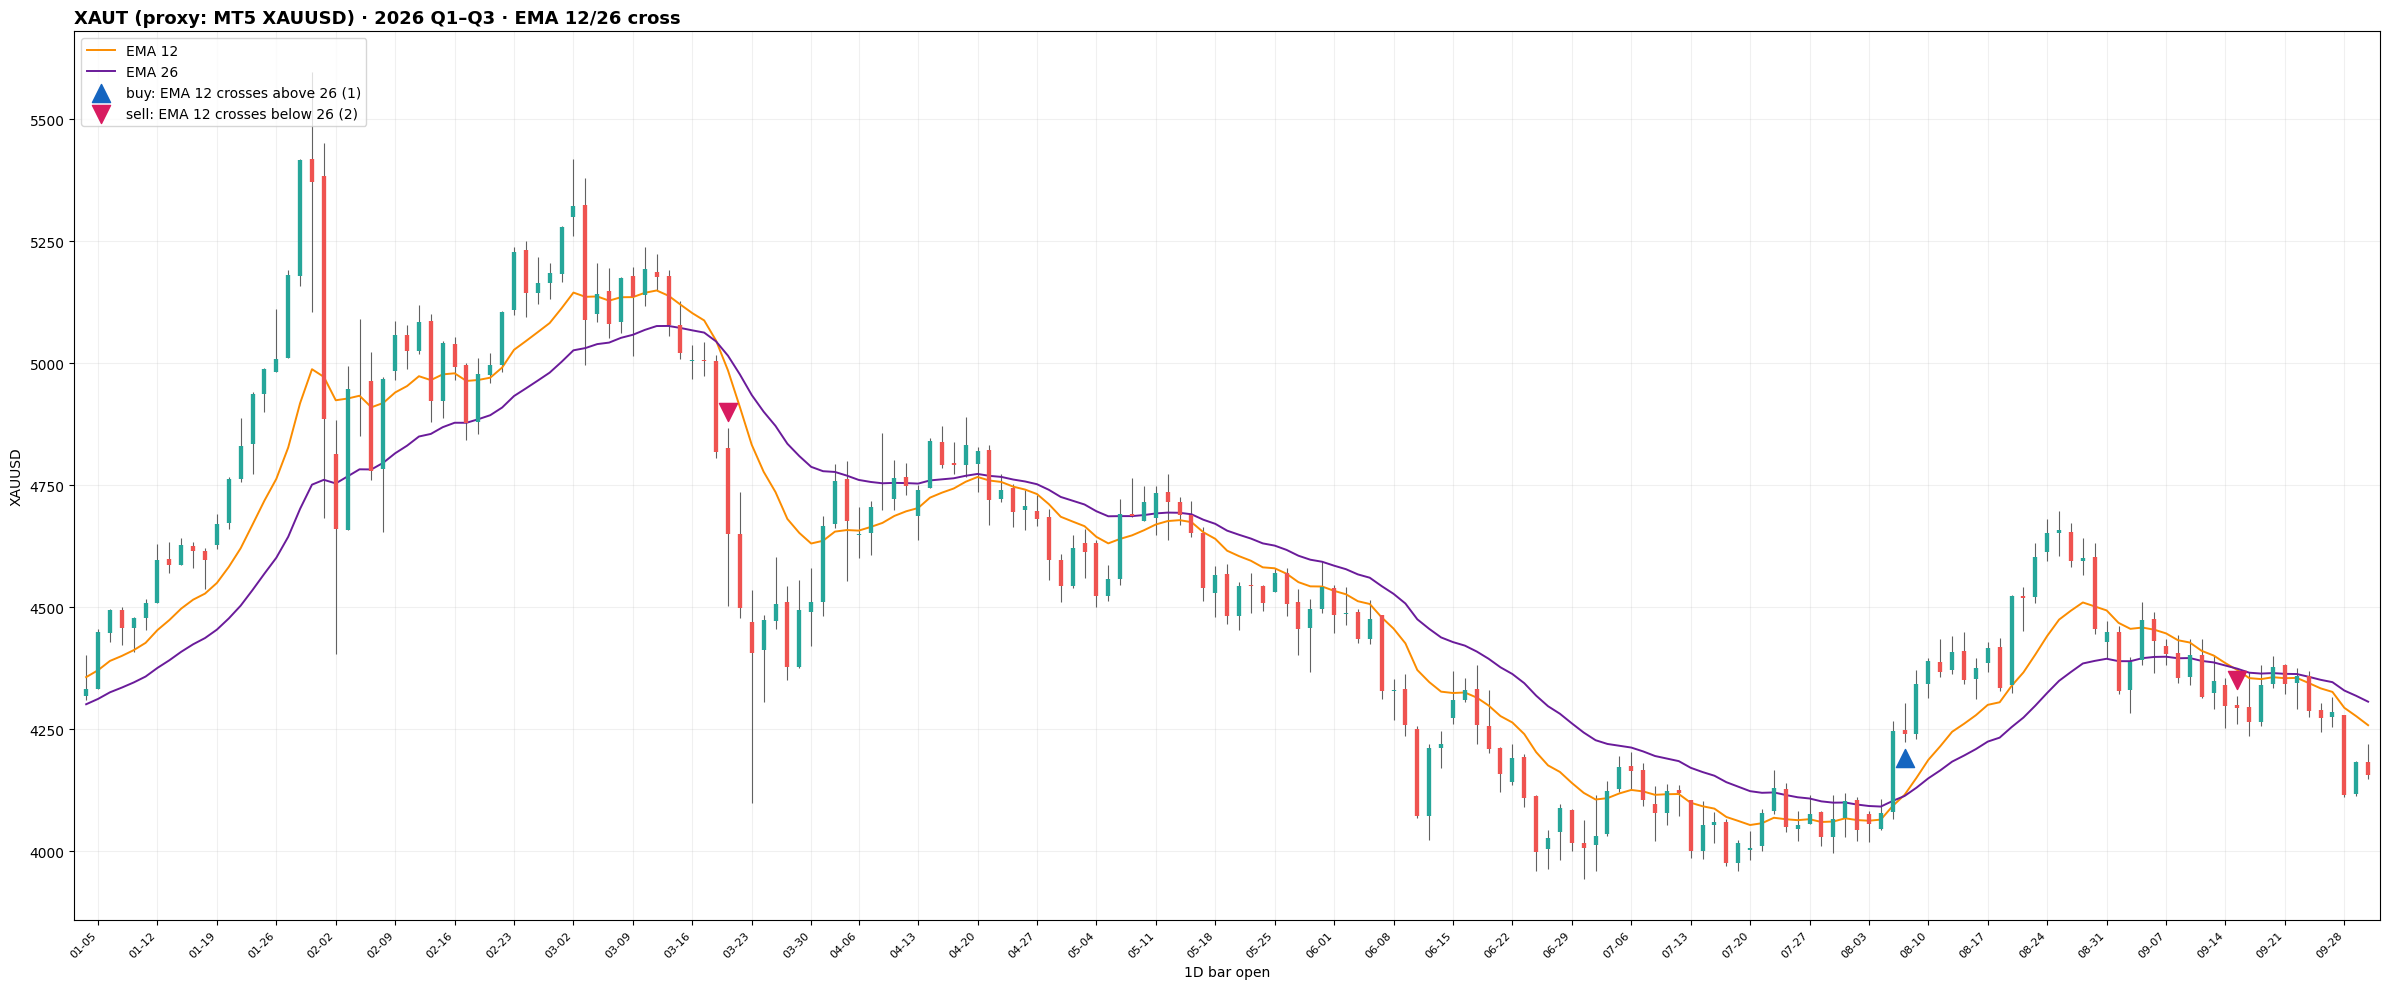

In [5]:
plot_ema_signals(bars["XAUT"], f"XAUT (proxy: MT5 XAUUSD) · {LABEL} · EMA 12/26 cross", "XAUUSD")

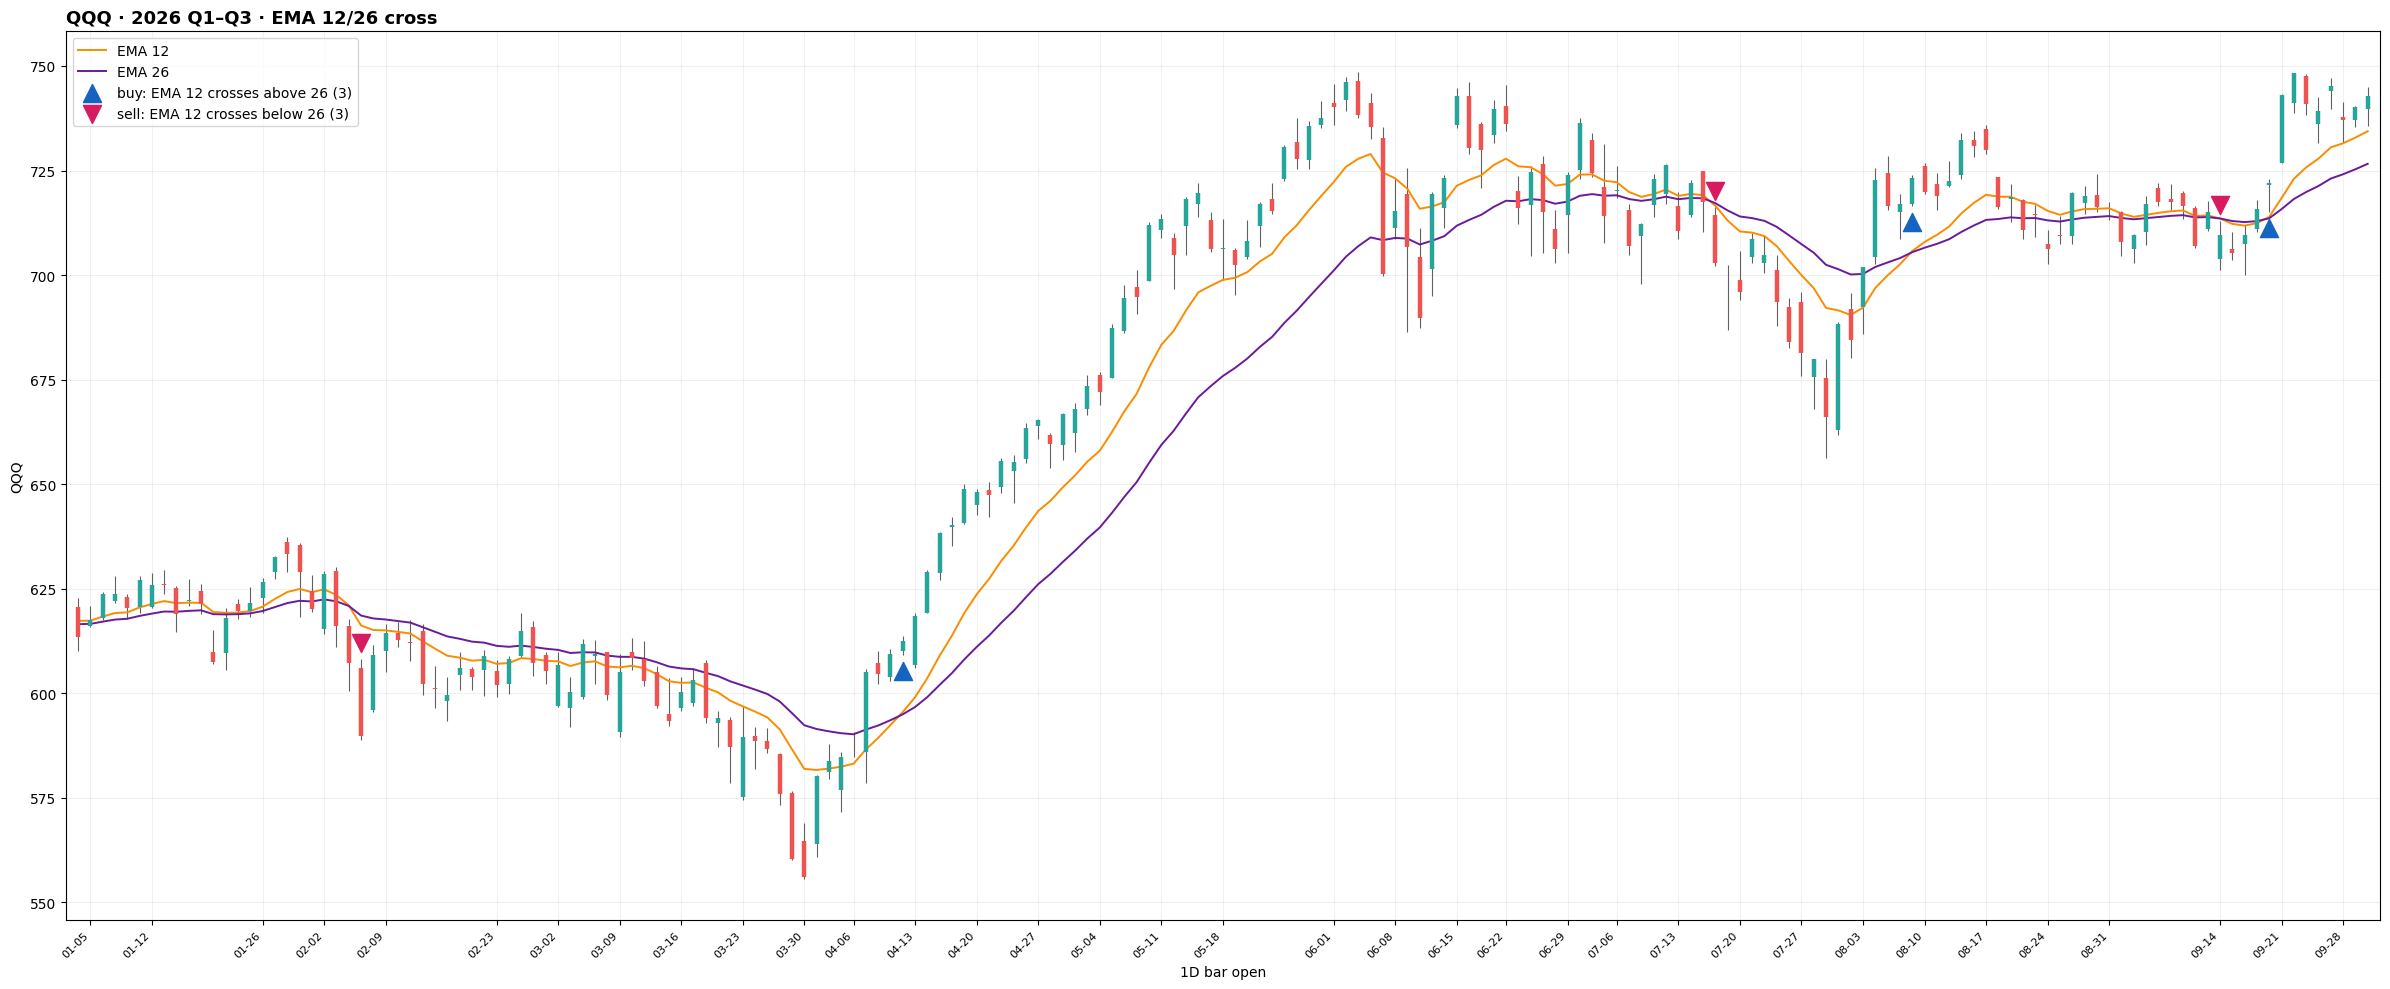

In [6]:
plot_ema_signals(bars["QQQ"], f"QQQ · {LABEL} · EMA 12/26 cross", "QQQ")